# Importar librerías y configurar rutas

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from packages import montecarlo as mc
from packages.bbva_graficos import (
    BBVA,
    configurar_graficos,
    formato_es,
    guardar_mpl,
    imprimir,
)

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import time
import copy

In [ ]:
# Número de trayectorias de Monte Carlo
NUM_SIMS = 100_000

# Semilla para que la división de datos sea reproducible
SEMILLA = 42

# Porcentajes para entrenamiento, validación y test
PROP_TRAIN = 0.70
PROP_VAL = 0.15

# Solo 3 entradas: una por activo
CANALES = [
    "ret_log_CAT",
    "ret_log_MRK",
    "ret_log_MSFT",
]

# Encontrar la raíz del proyecto al ejecutar desde un notebook
directorio_actual = Path.cwd()

RAIZ = next(
    (
        ruta
        for ruta in [directorio_actual, *directorio_actual.parents]
        if (ruta / "packages" / "montecarlo.py").exists()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError(
        "No encuentro la raíz del proyecto. "
        "Abre el notebook dentro del repositorio."
    )

RUTA_MC = RAIZ / "Datos" / "Transformados" / "montecarlo_independiente.npz"
RUTA_PARAMETROS = RAIZ / "outputs" / "parametros_montecarlo.json"
RUTA_SALIDA = RAIZ / "Datos" / "Transformados" / "rnn_dataset.npz"

print("Raíz del proyecto:", RAIZ)
print("Archivo Monte Carlo:", RUTA_MC)
print("Archivo de salida:", RUTA_SALIDA)

Raíz del proyecto: c:\BDATA 3\26_27_R09_Azul_Claro
Archivo Monte Carlo: c:\BDATA 3\26_27_R09_Azul_Claro\Datos\Transformados\montecarlo_independiente.npz
Archivo de salida: c:\BDATA 3\26_27_R09_Azul_Claro\Datos\Transformados\rnn_dataset.npz


# Comprobar los parámetros de Monte Carlo

In [2]:
assert RUTA_PARAMETROS.exists(), (
    f"No encuentro el archivo: {RUTA_PARAMETROS}"
)

parametros = json.loads(
    RUTA_PARAMETROS.read_text(encoding="utf-8")
)

assert np.array_equal(
    np.ravel(parametros["sigma"]),
    mc.SIGMA
), (
    "La sigma del módulo Monte Carlo no coincide con la del JSON."
)

assert np.array_equal(
    np.array(parametros["rho"]),
    mc.RHO
), (
    "La rho del módulo Monte Carlo no coincide con la del JSON."
)

print("Sigma y rho coinciden con los parámetros guardados.")

Sigma y rho coinciden con los parámetros guardados.


# Cargar los datos simulados

In [3]:
assert RUTA_MC.exists(), (
    f"No encuentro {RUTA_MC}. "
    "Ejecuta primero el notebook de Monte Carlo."
)

datos = np.load(RUTA_MC, allow_pickle=False)

print("Contenido del archivo Monte Carlo:\n")

for clave in datos.files:
    print(
        f"{clave:20s} "
        f"forma = {str(datos[clave].shape):18s} "
        f"tipo = {datos[clave].dtype}"
    )

# Extraer las variables
X = datos["X"]
retornos = datos["retornos_log"]
G = datos["medias_geometricas"]
payoff = datos["payoff"]
Y = datos["Y"]
tiempos = datos["tiempos"]

Contenido del archivo Monte Carlo:

X                    forma = (100000, 20, 3)    tipo = float64
retornos_log         forma = (100000, 20, 3)    tipo = float64
medias_geometricas   forma = (100000, 3)        tipo = float64
payoff               forma = (100000,)          tipo = float64
Y                    forma = (100000, 20)       tipo = float64
id_simulacion        forma = (100000,)          tipo = int64
tiempos              forma = (20,)              tipo = float64
activos              forma = (3,)               tipo = <U4
S0                   forma = (3,)               tipo = float64
sigma                forma = (3,)               tipo = float64
rho                  forma = (3, 3)             tipo = float64
r                    forma = ()                 tipo = float64
TTM                  forma = ()                 tipo = int64
dt                   forma = ()                 tipo = float64
strike               forma = ()                 tipo = int64
semilla              forma = 

# Comprobar que los datos son correctos

In [4]:
assert X.shape == (NUM_SIMS, mc.NUM_PASOS, 3), (
    f"Forma inesperada de X: {X.shape}"
)

assert np.array_equal(datos["sigma"], mc.SIGMA)
assert np.array_equal(datos["rho"], mc.RHO)

assert np.array_equal(retornos, mc.retornos_log(X))
assert np.array_equal(G, mc.medias_geometricas(X))
assert np.array_equal(tiempos, mc.TIEMPOS)

assert payoff.shape == (NUM_SIMS,), (
    f"Forma inesperada del payoff: {payoff.shape}"
)

assert np.array_equal(Y[:, -1], payoff), (
    "El último valor de Y no coincide con el payoff."
)

# Prima inicial de referencia: media del payoff descontada hasta t=0
prima_t0 = payoff.mean() * np.exp(-mc.R * mc.TTM)

# Porcentaje de trayectorias con payoff positivo
pct_itm = 100 * (payoff > 0).mean()

print(f"Número de trayectorias: {len(payoff):,}")
print(f"Payoff medio al vencimiento: {payoff.mean():.6f}")
print(f"Prima inicial estimada: {prima_t0:.6f}")
print(f"Trayectorias con payoff positivo: {pct_itm:.3f}%")

Número de trayectorias: 100,000
Payoff medio al vencimiento: 0.310201
Prima inicial estimada: 0.295072
Trayectorias con payoff positivo: 44.129%


# Crear las entradas y el objetivo de la red

In [5]:
# ENTRADAS:
# 100.000 trayectorias, 20 pasos, 3 activos
entradas = retornos.astype(np.float32)

# OBJETIVO:
# Un único payoff al vencimiento por trayectoria
objetivo_payoff = payoff.astype(np.float32)

print("Forma de las entradas:", entradas.shape)
print("Forma del objetivo:", objetivo_payoff.shape)

Forma de las entradas: (100000, 20, 3)
Forma del objetivo: (100000,)


# Separar entrenamiento, validación y test

In [6]:
rng = np.random.default_rng(SEMILLA)

# Mezclamos todas las trayectorias excepto la número 0
resto = rng.permutation(np.arange(1, NUM_SIMS))

n_train = int(PROP_TRAIN * NUM_SIMS)
n_val = int(PROP_VAL * NUM_SIMS)

idx_train = np.sort(resto[:n_train])

idx_val = np.sort(
    resto[n_train:n_train + n_val]
)

idx_test = np.sort(
    np.concatenate((
        [0],
        resto[n_train + n_val:]
    ))
)

# Comprobar que no hay trayectorias repetidas ni perdidas
todos_indices = np.concatenate(
    (idx_train, idx_val, idx_test)
)

assert len(todos_indices) == NUM_SIMS
assert len(np.unique(todos_indices)) == NUM_SIMS
assert 0 in idx_test

print(f"Entrenamiento: {len(idx_train):,} trayectorias")
print(f"Validación:    {len(idx_val):,} trayectorias")
print(f"Test:          {len(idx_test):,} trayectorias")

Entrenamiento: 70,000 trayectorias
Validación:    15,000 trayectorias
Test:          15,000 trayectorias


# Guardar el conjunto de datos preparado

In [ ]:
RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)

np.savez(
    RUTA_SALIDA,

    # Entradas y objetivo principal de la red
    entradas=entradas,
    objetivo_payoff=objetivo_payoff,

    # Datos originales conservados
    X=X,
    retornos_log=retornos,
    medias_geometricas=G,
    payoff=payoff,
    Y=Y,
    tiempos=tiempos,

    # Nombres de los canales de entrada
    canales=np.array(CANALES),

    # División de los datos
    idx_train=idx_train,
    idx_val=idx_val,
    idx_test=idx_test,

    # Conservamos el escalado original de Y por compatibilidad
    media_Y=Y[idx_train].mean(),
    desv_Y=Y[idx_train].std(),

    semilla=SEMILLA,
)

# Resumen y comprobaciones finales

In [9]:
print("RESUMEN DEL CONJUNTO DE DATOS")
print("-" * 40)

print("Entradas:", entradas.shape)
print("Objetivo payoff:", objetivo_payoff.shape)

for nombre, indices in [
    ("Entrenamiento", idx_train),
    ("Validación", idx_val),
    ("Test", idx_test),
]:
    porcentaje_positivos = 100 * (
        objetivo_payoff[indices] > 0
    ).mean()

    print(
        f"{nombre}: {len(indices):,} trayectorias; "
        f"{porcentaje_positivos:.2f}% con payoff positivo"
    )

print("\nPrimeros 5 payoffs:")
print(objetivo_payoff[:5])

print("\n¿Hay valores no finitos en las entradas?",
      not np.isfinite(entradas).all())

print("¿Hay valores no finitos en el objetivo?",
      not np.isfinite(objetivo_payoff).all())

RESUMEN DEL CONJUNTO DE DATOS
----------------------------------------
Entradas: (100000, 20, 3)
Objetivo payoff: (100000,)
Entrenamiento: 70,000 trayectorias; 43.96% con payoff positivo
Validación: 15,000 trayectorias; 45.00% con payoff positivo
Test: 15,000 trayectorias; 44.05% con payoff positivo

Primeros 5 payoffs:
[0.03805653 0.         0.         0.440466   0.        ]

¿Hay valores no finitos en las entradas? False
¿Hay valores no finitos en el objetivo? False


# Gráfico de la distribución del payoff

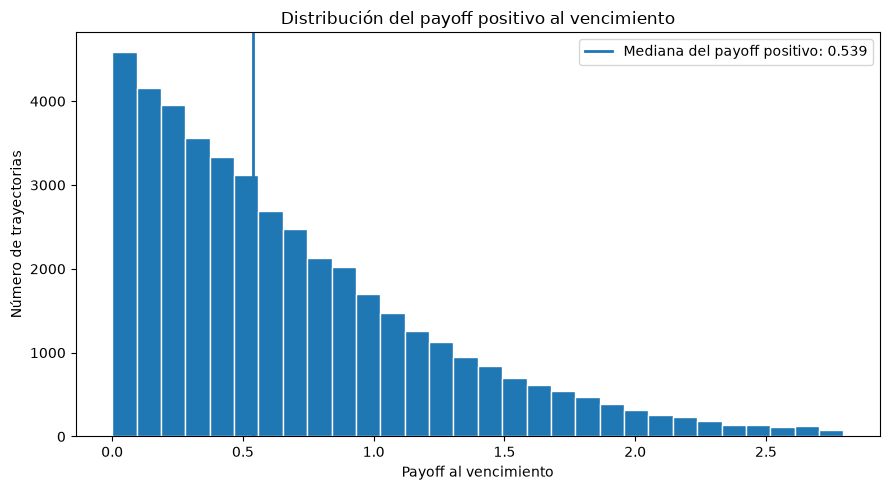

In [10]:
positivos = objetivo_payoff[objetivo_payoff > 0]

mediana = np.median(positivos)
p99 = np.percentile(positivos, 99)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    positivos,
    bins=30,
    range=(0, p99),
    edgecolor="white",
)

ax.axvline(
    mediana,
    linewidth=2,
    label=f"Mediana del payoff positivo: {mediana:.3f}",
)

ax.set_title("Distribución del payoff positivo al vencimiento")
ax.set_xlabel("Payoff al vencimiento")
ax.set_ylabel("Número de trayectorias")
ax.legend()

fig.tight_layout()
plt.show()

# Configurar el entrenamiento

In [12]:
SEMILLA = 42

torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

DISPOSITIVO = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH = 512
LR = 1e-3
MAX_EPOCAS = 100
PACIENCIA = 10
MIN_DELTA = 1e-6

print("Dispositivo:", DISPOSITIVO)

Dispositivo: cpu


# Cargar las entradas y el payoff final

In [ ]:
RUTA_DATASET = RAIZ / "Datos" / "Transformados" / "rnn_dataset.npz"

datos_np = np.load(RUTA_DATASET, allow_pickle=False)

print("Variables guardadas:")
print(datos_np.files)

Variables guardadas:
['entradas', 'objetivo_payoff', 'X', 'retornos_log', 'medias_geometricas', 'payoff', 'Y', 'tiempos', 'canales', 'idx_train', 'idx_val', 'idx_test', 'media_entradas', 'desv_entradas', 'media_payoff', 'desv_payoff', 'media_Y', 'desv_Y', 'semilla']


In [14]:
# Entradas: 100.000 trayectorias, 20 pasos y 3 activos
X = datos_np["entradas"].astype(np.float32)

# Payoff final: un único valor por trayectoria
if "objetivo_payoff" in datos_np.files:
    payoff = datos_np["objetivo_payoff"].astype(np.float32)
else:
    payoff = datos_np["payoff"].astype(np.float32)

print("Forma de X:", X.shape)
print("Forma del payoff:", payoff.shape)

Forma de X: (100000, 20, 3)
Forma del payoff: (100000,)


In [15]:
assert X.ndim == 3
assert X.shape[1:] == (20, 3)
assert payoff.shape == (len(X),)
assert np.isfinite(X).all()
assert np.isfinite(payoff).all()
assert (payoff >= 0).all()

print("Comprobaciones superadas.")

Comprobaciones superadas.


# Dividir los datos en entrenamiento, validación y test

In [16]:
idx_train = datos_np["idx_train"]
idx_val = datos_np["idx_val"]
idx_test = datos_np["idx_test"]

X_train = X[idx_train]
X_val = X[idx_val]
X_test = X[idx_test]

y_train = payoff[idx_train]
y_val = payoff[idx_val]
y_test = payoff[idx_test]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Entrenamiento: (70000, 20, 3) (70000,)
Validación: (15000, 20, 3) (15000,)
Test: (15000, 20, 3) (15000,)


# Escalar los datos

In [ ]:
# Escalado de las entradas, usando solo entrenamiento
media_X = X_train.mean(axis=(0, 1), keepdims=True)
desv_X = X_train.std(axis=(0, 1), keepdims=True)

desv_X = np.where(desv_X == 0, 1.0, desv_X)

X_train_s = (X_train - media_X) / desv_X
X_val_s = (X_val - media_X) / desv_X
X_test_s = (X_test - media_X) / desv_X

# Escalado del payoff final
media_y = float(y_train.mean())
desv_y = float(y_train.std())

if desv_y == 0:
    desv_y = 1.0

y_train_s = (y_train - media_y) / desv_y
y_val_s = (y_val - media_y) / desv_y
y_test_s = (y_test - media_y) / desv_y

print("Media del payoff:", media_y)
print("Desviación típica del payoff:", desv_y)

# Crear los conjuntos para PyTorch

In [ ]:
datos_train = TensorDataset(
    torch.tensor(X_train_s, dtype=torch.float32),
    torch.tensor(y_train_s, dtype=torch.float32)
)

datos_val = TensorDataset(
    torch.tensor(X_val_s, dtype=torch.float32),
    torch.tensor(y_val_s, dtype=torch.float32)
)

datos_test = TensorDataset(
    torch.tensor(X_test_s, dtype=torch.float32),
    torch.tensor(y_test_s, dtype=torch.float32)
)

loader_train = DataLoader(
    datos_train,
    batch_size=BATCH,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEMILLA)
)

loader_val = DataLoader(
    datos_val,
    batch_size=4096,
    shuffle=False
)

print("Conjuntos preparados.")

# Definir la red recurrente

In [ ]:
class RedPayoffFinal(nn.Module):

    def __init__(self, tipo, n_entrada=3, n_oculta=64):
        super().__init__()

        capa = {
            "rnn": nn.RNN,
            "lstm": nn.LSTM,
            "gru": nn.GRU
        }[tipo]

        self.recurrente = capa(
            input_size=n_entrada,
            hidden_size=n_oculta,
            num_layers=1,
            batch_first=True
        )

        self.lineal = nn.Linear(n_oculta, 1)

    def forward(self, x):

        secuencia, _ = self.recurrente(x)

        # Solo usamos la representación del paso 20
        ultimo_paso = secuencia[:, -1, :]

        # Un payoff por trayectoria
        salida = self.lineal(ultimo_paso).squeeze(-1)

        return salida

# Crear la función de entrenamiento

In [ ]:
def entrenar_payoff(modelo, lr=LR):

    modelo = modelo.to(DISPOSITIVO)

    optimizador = torch.optim.Adam(
        modelo.parameters(),
        lr=lr
)

    perdida = nn.MSELoss()

    historial = {
        "train": [],
        "val": []
    }

    mejor_val = float("inf")
    mejor_estado = None
    mejor_epoca = 0
    sin_mejora = 0

    inicio = time.perf_counter()

    for epoca in range(1, MAX_EPOCAS + 1):

        # Entrenamiento
        modelo.train()
        suma_train = 0.0

        for xb, yb in loader_train:
            xb = xb.to(DISPOSITIVO)
            yb = yb.to(DISPOSITIVO)

            optimizador.zero_grad()

            pred = modelo(xb)
            loss = perdida(pred, yb)

            loss.backward()

            nn.utils.clip_grad_norm_(
                modelo.parameters(), 1.0
            )

            optimizador.step()

            suma_train += loss.item() * len(xb)

        loss_train = suma_train / len(datos_train)

        # Validación
        modelo.eval()
        suma_val = 0.0

        with torch.no_grad():
            for xb, yb in loader_val:
                xb = xb.to(DISPOSITIVO)
                yb = yb.to(DISPOSITIVO)

                pred = modelo(xb)
                loss = perdida(pred, yb)

                suma_val += loss.item() * len(xb)

        loss_val = suma_val / len(datos_val)

        historial["train"].append(loss_train)
        historial["val"].append(loss_val)

        # Guardar el mejor modelo
        if loss_val < mejor_val - MIN_DELTA:
            mejor_val = loss_val
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0:
            print(
                f"Época {epoca:3d} | "
                f"Train: {loss_train:.5f} | "
                f"Val: {loss_val:.5f}"
            )

        if sin_mejora >= PACIENCIA:
            print("Parada temprana.")
            break

    tiempo = time.perf_counter() - inicio

    modelo.load_state_dict(mejor_estado)

    return modelo, {
        "historial": historial,
        "mejor_epoca": mejor_epoca,
        "mejor_val": mejor_val,
        "epocas": epoca,
        "tiempo": tiempo
    }

# Entrenar las tres arquitecturas

In [ ]:
# Busqueda de hiperparametros
estructuras = {
    "RNN simple": "rnn",
    "LSTM": "lstm",
    "GRU": "gru"
}

# Valores que vamos a probar
NEURONAS = [32, 64, 128]
TASAS_APRENDIZAJE = [1e-3, 3e-4]

# Guardar el mejor modelo y su configuración para cada arquitectura
modelos = {}
resultados_entrenamiento = {}
configuraciones = {}

# Guardar los resultados de TODAS las configuraciones probadas
todas_las_pruebas = []

# Recorrer las tres arquitecturas
for nombre, tipo in estructuras.items():

    print(f"\n{'=' * 50}")
    print(f"Buscando hiperparámetros para: {nombre}")
    print("=" * 50)

    mejor_val_arquitectura = float("inf")
    mejor_modelo_arquitectura = None
    mejor_resultado_arquitectura = None
    mejor_configuracion = None

    # Probar cada combinación de neuronas y tasa de aprendizaje
    for n_oculta in NEURONAS:
        for lr in TASAS_APRENDIZAJE:

            print(
                f"\nProbando {nombre}: "
                f"neuronas={n_oculta}, lr={lr}"
            )

            # Fijar las semillas para reproducibilidad
            torch.manual_seed(SEMILLA)
            np.random.seed(SEMILLA)

            # Crear el modelo
            modelo = RedPayoffFinal(
                tipo=tipo,
                n_entrada=3,
                n_oculta=n_oculta
            )

            # Entrenar con la tasa de aprendizaje probada
            modelo, resultado = entrenar_payoff(
                modelo,
                lr=lr
            )

            # Registrar los resultados de esta configuración
            todas_las_pruebas.append({
                "Arquitectura": nombre,
                "Neuronas ocultas": n_oculta,
                "Tasa de aprendizaje": lr,
                "MSE validación": resultado["mejor_val"],
                "Mejor época": resultado["mejor_epoca"],
                "Tiempo (s)": resultado["tiempo"]
            })

            # Elegir la mejor configuración usando validación
            if resultado["mejor_val"] < mejor_val_arquitectura:

                mejor_val_arquitectura = resultado["mejor_val"]
                mejor_modelo_arquitectura = modelo
                mejor_resultado_arquitectura = resultado

                mejor_configuracion = {
                    "arquitectura": nombre,
                    "n_oculta": n_oculta,
                    "lr": lr,
                    "num_capas": 1
                }

    # Guardar la mejor configuración de esta arquitectura
    modelos[nombre] = mejor_modelo_arquitectura
    resultados_entrenamiento[nombre] = mejor_resultado_arquitectura
    configuraciones[nombre] = mejor_configuracion

    print(f"\nMejor configuración para {nombre}:")
    print(mejor_configuracion)
    print(
        "Mejor MSE de validación:",
        mejor_val_arquitectura
    )


# --------------------------------------------------
# TABLA 1: todas las configuraciones probadas
# --------------------------------------------------

tabla_todas_las_pruebas = (
    pd.DataFrame(todas_las_pruebas)
    .sort_values("MSE validación")
    .reset_index(drop=True)
)

print("\nRESULTADOS DE TODAS LAS CONFIGURACIONES")
display(tabla_todas_las_pruebas)


# --------------------------------------------------
# TABLA 2: mejor configuración de cada arquitectura
# --------------------------------------------------

tabla_hiperparametros = pd.DataFrame([
    {
        "Arquitectura": nombre,
        "Neuronas ocultas": configuraciones[nombre]["n_oculta"],
        "Tasa de aprendizaje": configuraciones[nombre]["lr"],
        "Capas": configuraciones[nombre]["num_capas"],
        "MSE validación": resultados_entrenamiento[nombre]["mejor_val"],
        "Mejor época": resultados_entrenamiento[nombre]["mejor_epoca"],
        "Tiempo (s)": resultados_entrenamiento[nombre]["tiempo"]
    }
    for nombre in estructuras
]).sort_values("MSE validación").reset_index(drop=True)

print("\nMEJOR CONFIGURACIÓN DE CADA ARQUITECTURA")
display(tabla_hiperparametros)


# Comparar las predicciones en test

In [ ]:
def predecir_payoff(modelo, X_escalado):

    modelo.eval()
    predicciones = []

    with torch.no_grad():
        for inicio in range(0, len(X_escalado), 8192):

            xb = torch.tensor(
                X_escalado[inicio:inicio + 8192],
                dtype=torch.float32,
                device=DISPOSITIVO
            )

            pred = modelo(xb).cpu().numpy()
            predicciones.append(pred)

    pred_escalado = np.concatenate(predicciones)

    # Deshacer el escalado y asegurar payoff >= 0
    pred_real = pred_escalado * desv_y + media_y

    return np.maximum(pred_real, 0)


predicciones_test = {}
filas = []

for nombre, modelo in modelos.items():

    pred = predecir_payoff(modelo, X_test_s)
    predicciones_test[nombre] = pred

    filas.append({
        "Modelo": nombre,
        "Neuronas ocultas": configuraciones[nombre]["n_oculta"],
        "Tasa de aprendizaje": configuraciones[nombre]["lr"],
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "Mejor epoca": resultados_entrenamiento[nombre]["mejor_epoca"],
        "Tiempo (s)": resultados_entrenamiento[nombre]["tiempo"]
    })

tabla_resultados = pd.DataFrame(filas).sort_values("RMSE")

tabla_resultados

In [ ]:
mejor_nombre = min(
    resultados_entrenamiento,
    key=lambda nombre: resultados_entrenamiento[nombre]["mejor_val"]
)

mejor_modelo = modelos[mejor_nombre]

print("Modelo elegido por validación:", mejor_nombre)

# Calcular la prima inicial estimada

In [ ]:
# Calcular la prima inicial estimada y compararla con Monte Carlo

r = mc.R
T = mc.TTM

# Payoffs predichos por la red para las trayectorias de test
payoffs_predichos = predecir_payoff(mejor_modelo, X_test_s)

# Prima estimada por la red
media_payoff_predicho = payoffs_predichos.mean()
prima_red_test = np.exp(-r * T) * media_payoff_predicho

# Prima de referencia de Monte Carlo para esas mismas trayectorias
prima_mc_test = np.exp(-r * T) * y_test.mean()

print(f"Modelo elegido: {mejor_nombre}")
print(f"Prima estimada por la red: {prima_red_test:.6f}")
print(f"Prima de referencia MC (test): {prima_mc_test:.6f}")
print(f"Diferencia absoluta: {abs(prima_red_test - prima_mc_test):.6f}")


# Guardar el modelo elegido

In [ ]:
# Guardar el modelo elegido y sus hiperparámetros

CARPETA_MODELOS = RAIZ / "modelos"
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

config_final = configuraciones[mejor_nombre]

torch.save(
    {
        "tipo": estructuras[mejor_nombre],
        "n_entrada": 3,
        "n_oculta": config_final["n_oculta"],
        "num_capas": config_final["num_capas"],
        "lr": config_final["lr"],
        "estado": mejor_modelo.state_dict(),
        "media_X": media_X,
        "desv_X": desv_X,
        "media_y": media_y,
        "desv_y": desv_y,
        "nombre": mejor_nombre
    },
    CARPETA_MODELOS / "red_payoff_final.pt"
)

print("Modelo elegido:", mejor_nombre)
print("Hiperparámetros:", config_final)
print("Modelo guardado correctamente.")
